In [2]:

import operator
import os
from datetime import datetime
from typing import Annotated, Literal, Optional, TypedDict

from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain_core.messages import AIMessage, SystemMessage
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.types import Send
from pydantic import BaseModel, Field
from pprint import pprint
import nest_asyncio

nest_asyncio.apply()



In [3]:
_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    max_tokens=2048)
 

In [4]:
today = datetime.now()
print(today)



supervisor_prompt = f"""
You are a travel supervisor for Indian travellers.
Decide which agents should handle the user's request:
- rail: trains, PNR, train status
- bus: bus routes, schedules, fares
- flight: flights

Rules:
1. If the user names a mode (train, bus, flight), choose only that agent.
2. If the user gives only a route (like "Pune to Mumbai"), choose all three.
3. If the message is not about travel, set needs_clarification=true and ask what they need.
4. If no date is mentioned, use today's date. Today is {today}.
Never answer the travel question yourself. Only decide the routing.
"""


2026-11-05 08:57:09.226089


In [5]:
pprint(supervisor_prompt)


('\n'
 'You are a travel supervisor for Indian travellers.\n'
 "Decide which agents should handle the user's request:\n"
 '- rail: trains, PNR, train status\n'
 '- bus: bus routes, schedules, fares\n'
 '- flight: flights\n'
 '\n'
 'Rules:\n'
 '1. If the user names a mode (train, bus, flight), choose only that agent.\n'
 '2. If the user gives only a route (like "Pune to Mumbai"), choose all '
 'three.\n'
 '3. If the message is not about travel, set needs_clarification=true and ask '
 'what they need.\n'
 "4. If no date is mentioned, use today's date. Today is 2026-11-05 "
 '08:57:09.226089.\n'
 'Never answer the travel question yourself. Only decide the routing.\n')


## Global Data

In [6]:
import re

# City -> IATA airport code
AIRPORTS = {
    "pune": "PNQ", "mumbai": "BOM", "delhi": "DEL", "bengaluru": "BLR",
    "chennai": "MAA", "kolkata": "CCU", "hyderabad": "HYD", "ahmedabad": "AMD",
    "goa": "GOI", "jaipur": "JAI", "nagpur": "NAG", "lucknow": "LKO",
    "kochi": "COK", "nashik": "ISK", "indore": "IDR", "bhopal": "BHO",
    "surat": "STV", "thiruvananthapuram": "TRV", "chandigarh": "IXC", "patna": "PAT",
}

# City -> main railway station code
STATIONS = {
    "pune": "PUNE", "mumbai": "CSMT", "delhi": "NDLS", "bengaluru": "SBC",
    "chennai": "MAS", "kolkata": "HWH", "hyderabad": "SC", "ahmedabad": "ADI",
    "goa": "MAO", "jaipur": "JP", "nagpur": "NGP", "lucknow": "LKO",
    "nashik": "NK", "indore": "INDB", "bhopal": "BPL", "surat": "ST",
}

ALIASES = {
    "bangalore": "bengaluru", "bombay": "mumbai", "new delhi": "delhi",
    "calcutta": "kolkata", "madras": "chennai", "trivandrum": "thiruvananthapuram",
    "panaji": "goa", "madgaon": "goa",
}


def _norm(name: str) -> str:
    n = re.sub(r"\s+", " ", name.strip().lower())
    return ALIASES.get(n, n)


def to_iata(name: str):
    """City name -> airport code. Passes through if already a 3-letter code."""
    n = _norm(name)
    if n in AIRPORTS:
        return AIRPORTS[n]
    return name.strip().upper() if re.fullmatch(r"[A-Za-z]{3}", name.strip()) else None


def to_station(name: str):
    """City name -> station code. Passes through if it already looks like a code."""
    n = _norm(name)
    if n in STATIONS:
        return STATIONS[n]
    s = name.strip()
    return s.upper() if re.fullmatch(r"[A-Za-z]{2,5}", s) and s.isupper() else None


### Flow
1. Supervisor
2. a. Train b. Flight c. Bus
3. Tools Distribution

### Section --> [ Train Agent ]

#### Tools [Train]

In [7]:
# Railway Tools
from langchain_core.tools import tool
from dotenv import load_dotenv
import requests
from datetime import date as date_cls

import os


load_dotenv()


RAILRADAR_API_KEY="rg_c0e3888d36714af98bdbcc682f62d063"






RAILRADAR_API_KEY = os.getenv("RAILRADAR_API_KEY")
_base = "https://api.railradar.in/v1"


def _call_api_for_trains(url, params=None):
    headers = {"Authorization": f"Bearer {RAILRADAR_API_KEY}"}
    response = requests.get(f"{_base}{url}", headers=headers, params=params, timeout=15)
    response.raise_for_status()
    return response.json()


@tool
def search_train(source: str, destination: str, date: str = "") -> dict:
    """Search trains between two stations.

    Args:
        source: Origin station code (e.g. "PUNE").
        destination: Destination station code (e.g. "CSMT").
        date: Optional date in YYYY-MM-DD format; defaults to today.

    Returns the trains running between the two stations on that date.
    This tool only searches; it never books tickets.
    """
    try:
        date = date or date_cls.today().isoformat()
        data = _call_api_for_trains(
            url=f"/trains/between/{source}/{destination}",
            params={"date": date},
        )        
        
        
        response = [f"{i['train']['number']}, {i['train']['name']}" 
            for i  in data['data']["trains"][0:3] ]
        
        
        return response

    except Exception as e:
        print(f"%%% {e} ")




In [8]:
from langchain.agents import create_agent



_sys_prompt_train =  """
You are a Train agent. Help customers using the tools you have.
Tools:
    - search_train: find trains for a given `source` and `destination`.

Rules:
- Always pass Indian Railways station CODES, not city names (Pune = PUNE,
  Mumbai = CSMT, Delhi = NDLS). If a city has several stations and the user
  didn't specify, pick the main one and mention the choice.
- If the tool returns no trains or an error, tell the user and try a
  different station code before giving up.
"""


RailwayAgent = create_agent(_llm,tools=[search_train],system_prompt=_sys_prompt_train)


### Section --> [ Bus Agent ]

#### Tools [Bus]

In [9]:
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from dotenv import load_dotenv
import requests
from datetime import date as date_cls
import os
load_dotenv()


TAVILY_API_KEY="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"
tavily = TavilySearchResults(max_results=3)

source = "pune"
destination = "mumbai"


def _call_api_for_flights(query):
    response = tavily.invoke({"query":query})
    return response
    
    

@tool
def search_buses(source, destination):
    """Search the web for bus options between two cities in India.

    Args:
        source: Origin city (e.g. "Pune").
        destination: Destination city (e.g. "Mumbai").

    Returns web results about bus operators, timings, fares and booking links.
    This tool only searches; it never books tickets.
    """

    try:
        query = f"{source} to {destination} bus operators timings fare booking"
        response = _call_api_for_flights(query)
        return response
    except Exception as e:
        print(f"%%% ERROR: {e}")
        return []
        


C:\Users\wpnx\AppData\Local\Temp\ipykernel_9116\2648340218.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults
C:\Users\wpnx\AppData\Local\Temp\ipykernel_9116\2648340218.py:11: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults(max_results=3)


In [10]:
_sys_prompt_train =  """
You are a Bus agent. Help customers find bus options using the tools you have.
Tools:
    - search_buses: find bus operators, timings, fares and booking links
      between two cities.

Rules:
- Pass plain city names (e.g. "Pune", "Mumbai").
- Summarize the results briefly: operators, typical timings, fare range, and
  a booking link if one appears. Don't invent fares or timings that aren't
  in the results.
- You only search; you cannot book tickets.
"""

BusAgent = create_agent(model=_llm, tools=[search_buses],system_prompt= _sys_prompt_train )


In [11]:
# BusAgent.invoke({"messages":["I want to travel from Pune to mumbai"]})


### Section --> [ Flight Agent ]

#### Tools [Flight]

In [12]:
import os

import requests
from dotenv import load_dotenv
from langchain_core.tools import tool

load_dotenv()

# AVIATIONSTACK_API_KEY = os.getenv("AVIATIONSTACK_API_KEY")
AVIATIONSTACK_API_KEY="be8491c85ad7d4ba8d90b69bff1f6c6e"

# Free plan only supports HTTP. On a paid plan, switch to https.
_AVIATION_BASE = "http://api.aviationstack.com/v1"


@tool
def search_flights(source: str, destination: str, limit: int = 3) -> list:
    """Search flights between two airports.

    Args:
        source: Departure airport IATA code (e.g. "DEL", "PNQ").
        destination: Arrival airport IATA code (e.g. "BOM").
        limit: Max number of flights to return (default 10).

    Returns a list of flights with airline, flight number, status and
    scheduled departure/arrival times. This tool only searches; it never
    books tickets.
    """
    params = {
        "access_key": AVIATIONSTACK_API_KEY,
        "dep_iata": to_iata(source).upper(),
        "arr_iata": to_iata(destination).upper(),
        "limit": limit,
    }
    response = requests.get(f"{_AVIATION_BASE}/flights", params=params, timeout=15)
    response.raise_for_status()
    data = response.json()

    if "error" in data:
        return [{"error": data["error"].get("message", "AviationStack error")}]

    flights = []
    for f in data.get("data", []):
        flights.append({
            "airline": f["airline"]["name"],
            "flight": f["flight"]["iata"],
            "status": f["flight_status"],
            "date": f["flight_date"],
            "from": f["departure"]["airport"],
            "departure": f["departure"]["scheduled"],
            "terminal": f["departure"].get("terminal"),
            "to": f["arrival"]["airport"],
            "arrival": f["arrival"]["scheduled"],
        })
    
    if flights:
        return flights
    
    return "no results found"


In [13]:
_prompt_flight = """
You are a Flight agent. Help customers find flights using the tools you have.
Tools:
    - search_flights: find flights between two airports.

Rules:
- Always pass IATA airport CODES, not city names (Pune = PNQ, Mumbai = BOM,
  Delhi = DEL, Bengaluru = BLR). If a city has several airports, pick the
  main one and mention the choice.
- The tool returns current/recent flight data, not a future timetable or
  fares. Say so if the user asks about a future date or prices.
- If the tool returns no flights or an error, tell the user plainly.
- You only search; you cannot book tickets.
"""

FlightAgent = create_agent(model=_llm, tools=[search_flights], system_prompt=_prompt_flight)


In [14]:
# FlightAgent.invoke({"messages":["Flights from mumbai to nagpur "]})


## Supervisor

In [18]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict,Annotated, List ,Literal
from langgraph.graph.message import add_messages
from typing import Annotated, Literal, TypedDict
from pydantic import BaseModel, Field
from langgraph.types import Send


In [55]:
class AgentState(TypedDict, total=False):
    question: str   
    selected_agents: list[str]
    answer: Annotated[List[str], operator.add]
    final_answer: str


In [43]:
class routerSchema(BaseModel):
    selected_agents : list[Literal["train","bus", "flight"]] = Field(description="Selected the respective agents")


In [69]:
agents_collection = {"train": RailwayAgent, "bus": BusAgent, "flight": FlightAgent}


def ROUTER(state):
    print("@@@ ---agent node--- ")

    Q = state["question"]
    resp = _llm.with_structured_output(routerSchema).invoke(Q)
    
    selected_agents = resp.selected_agents or ["train","bus", "flight"]
    
    ### run llel
    
    
    fanout = []
    
    for _a in selected_agents:
        fanout.append(Send("agent_node",{"name": _a, "question":Q}  ))
    
    print(f"**** {fanout} ")    
    
    return fanout


def agent_node(payload):
    print("@@@ ---agent node--- ")
    name,question = payload['name'], payload['question']
    
    print(f"TRACK:::  {name}")
    
    try:
        op = agents_collection[name].invoke({"messages":[question]})
        resp = op['messages'][-1].content
    except Exception as e:
        resp = f" --FAILED-- {e}"
    
    print(f"TRACK:::  {resp}")
    
    
    return {"answer": [f" ==={name}=== {resp} \n\n"] }


def output_node(state):
    print("@@@  --output node-- ")
    resp = _llm.invoke(f"Using given infomation create a formamted summarize human readable answer . Question{state['question']} , Answer: {state['answer']}")
    
    return {"final_answer": resp.content}
    
    



# def runAgent(state):
#     _collection = []
#     Q = state["messages"][-1].content
#     selected_agents = state['selected_agents']
    
#     for agent_name in selected_agents:
#         op = agents_collection[agent_name].invoke({"messages":[Q]})
#         agent_answer = op['messages'][-1].content or "no answer"
#         _collection.append(f"Agent: {agent_name} \n {agent_answer} \n ======== ")
    
#     final_answer = " ".join(_collection)
    
#     return {"answer": final_answer, "messages": [final_answer]}
    
    
    

In [70]:
# builder = StateGraph(AgentState)
# builder.add_node("router", ROUTER)
# builder.add_node("run_agents", runAgent)
# builder.add_edge(START, "router")
# builder.add_edge("router", "run_agents")
# builder.add_edge("run_agents", END)
# graph = builder.compile()


builder = StateGraph(AgentState)
builder.add_node("agent_node",agent_node)
builder.add_node("output_node", output_node)
builder.add_conditional_edges(START, ROUTER, ['agent_node'])
builder.add_edge("agent_node", "output_node")
builder.add_edge("output_node",END)
graph = builder.compile()



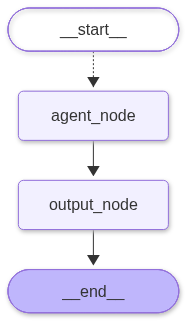

In [71]:
from IPython.display import Image,display_png
Image(graph.get_graph().draw_mermaid_png())


In [72]:
result = graph.invoke({"question": "Pune to Mumbai by bus"})


@@@ ---agent node--- 
**** [Send(node='agent_node', arg={'name': 'bus', 'question': 'Pune to Mumbai by bus'})] 
@@@ ---agent node--- 
TRACK:::  bus
TRACK:::  **Pune → Mumbai (by road)**  

| What | Details |
|------|---------|
| **Typical journey time** | ~3 h 50 min (148 km via the Mumbai‑Pune Expressway). |
| **First & last buses** | First bus around **00:10 am** (some operators start at 01:00 am), last bus around **23:59 pm**. |
| **Operators & types** | • **MSRTC (Shivneri & Shivshahi)** – AC Volvo & semi‑luxury coaches (departure from Swargate, Shivajinagar, Wakad, Pune Station). <br>• **RedBus‑listed private operators** – e.g., Prasanna Purple Mobility, Neeta Tours & Travels, SHREE GANESH TOURS, IntrCity SmartBus, VRL Travels, Dolphin Travel House, Jay Khodiyar Travels, Parshwanath Holidays, etc. |
| **Fare range** | From **₹160** (non‑AC seater) up to **₹9,999** (premium AC/sleeper). Most AC Volvo/sem‑luxury fares fall between **₹450–₹700**. |
| **Booking links** | • **RedBus** 

In [73]:
pprint(result)


{'answer': [' ===bus=== **Pune\u202f→\u202fMumbai (by road)**  \n'
            '\n'
            '| What | Details |\n'
            '|------|---------|\n'
            '| **Typical journey time** | ~3\u202fh\u202f50\u202fmin (148\u202f'
            'km via the Mumbai‑Pune Expressway). |\n'
            '| **First & last buses** | First bus around **00:10\u202fam** '
            '(some operators start at 01:00\u202fam), last bus around '
            '**23:59\u202fpm**. |\n'
            '| **Operators & types** | • **MSRTC (Shivneri & Shivshahi)** – AC '
            'Volvo & semi‑luxury coaches (departure from Swargate, '
            'Shivajinagar, Wakad, Pune Station). <br>• **RedBus‑listed private '
            'operators** – e.g., Prasanna Purple Mobility, Neeta Tours & '
            'Travels, SHREE GANESH TOURS, IntrCity SmartBus, VRL Travels, '
            'Dolphin Travel House, Jay Khodiyar Travels, Parshwanath Holidays, '
            'etc. |\n'
            '| **Fare range** | From **

In [ ]:
pprint(result['final_answer'])


('**Pune\u202f→\u202fMumbai (by road)**  \n'
 '\n'
 '| What | Details |\n'
 '|------|---------|\n'
 '| **Typical journey time** | ~3\u202fh\u202f50\u202fmin (148\u202fkm via the '
 'Mumbai‑Pune Expressway) |\n'
 '| **First & last buses** | First around **00:10\u202fam** (some start at '
 '01:00\u202fam); last around **23:59\u202fpm** |\n'
 '| **Operators & types** | • **MSRTC (Shivneri & Shivshahi)** – AC Volvo & '
 'semi‑luxury coaches (departures from Swargate, Shivajinagar, Wakad, Pune '
 'Station)  <br>• **Private operators** (listed on RedBus) – e.g., Prasanna '
 'Purple Mobility, Neeta Tours & Travels, SHREE GANESH TOURS, IntrCity '
 'SmartBus, VRL Travels, Dolphin Travel House, Jay Khodiyar Travels, '
 'Parshwanath Holidays, etc. |\n'
 '| **Fare range** | ₹160 (non‑AC seater)\u202f–\u202f₹9,999 (premium '
 'AC/sleeper). Most AC Volvo/sem‑luxury seats cost **₹450–₹700**. |\n'
 '| **Booking links** | • **RedBus** – '
 '<https://www.redbus.in/bus-tickets/pune-to-mumbai>  <br>• **Ab

In [ ]:
def create_question(Q):
    return {"question": Q}


In [ ]:
graph.invoke(create_question("what is source and destionation"))


@@@ ---agent node--- 


BadRequestError: Error code: 400 - {'error': {'message': 'Tool choice is required, but model did not call a tool', 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '**Source** and **destination** are the two key points that define any journey or trip:\n\n| Term | What it means | Typical examples |\n|------|----------------|------------------|\n| **Source** | The place where you begin your travel. It’s the origin point of your trip. | • Your home or office <br>• A train station, bus stop, or airport you’re leaving from <br>• A city or region you’re departing from |\n| **Destination** | The place where you intend to arrive. It’s the end point of your trip. | • A hotel, attraction, or event venue <br>• A city, town, or country you’re traveling to <br>• A specific address or landmark |\n\n### Why they matter\n- **Planning**: Knowing both lets you choose the right mode of transport (train, bus, flight, car, etc.) and book tickets or reservations.\n- **Routing